<hr>

# **<span style="color: #87CEEB;"> CS437 / CS5317 / EE414 / EE513 Deep Learning Programming Assignment 3 Part-1C</span>**

<hr>

# <span style="color: #9370DB;">**Submission Guidelines**</span>

- <span style="color: #9370DB;">Please rename the file to `<RollNumber>_PA3_1C`.</span>
- <span style="color: #9370DB;">Please also submit a **.py** file of every Notebook. You can do this by exporting your **ipynb** to a Python script.</span>
- <span style="color: #9370DB;">Please submit a zipped folder of both your Jupyter Notebooks and Python script files.</span>

<hr>


### Name: Sameer Rahil
### Roll Number: 27100162

# <span style="color:#9370DB;">Assignment Overview</span>

In this assignment we will implement and analyze **CycleGAN**, a generative adversarial network designed for **unpaired image-to-image translation**.

Unlike supervised translation models that require paired data, CycleGAN learns mappings between two domains using **unpaired datasets**.

In this assignment, you will:

- Understand the **CycleGAN architecture**
- Train and evaluate models on the **Horse2Zebra dataset**
- Perform **ablation experiments** to study the effect of different loss functions
- Fine-tune a pretrained model
- Evaluate results using **quantitative metrics**

The goal is to understand **why cycle consistency is crucial for stable domain translation**.

<hr>


# <span style="color:#9370DB;">Introduction to CycleGAN</span>

The key problem addressed by CycleGAN is learning mappings between two domains **without paired training data**.

Examples of tasks solved by CycleGAN include:

- Horse ↔ Zebra
- Summer ↔ Winter
- Monet Paintings ↔ Real Photos
- Day ↔ Night

Instead of requiring paired examples, CycleGAN enforces **cycle consistency**, which ensures that translating an image from one domain to another and back again reconstructs the original image.

Example:

Horse → Zebra → Horse


<img src="https://junyanz.github.io/CycleGAN/images/teaser.jpg" width="1000" height="900"/>
<h4></h4>
<h4><center>Image Source:  <a href="https://arxiv.org/pdf/1703.10593.pdf">Unpaired Image-to-Image Translation using Cycle-Consistent Adversarial Networks [C. Jun-Yan Zhu et al.]</a></center></h4>


# <span style="color:#9370DB;">Assignment Tasks</span>

This part of the assignment is divided into multiple stages.

### Stage 1: Dataset Download and Load Pretrained Model 

Download the horsetozebra dataset from kaggle and load the pretrained cycle GAN model. You may use a subset of data for ablation only so you have shorter training times. 

---

### Stage 2: Ablation Experiments

We intentionally remove important loss components to analyze their effect on model performance. 

Experiments include:

- Removing **cycle consistency loss**
- Removing **identity loss**

---

### Stage 3: Fine Tuning


Run the given pretrained model and fine-tune it and run for a (3-5) epochs. Use complete dataset.

---

### Stage 4: Evaluation

The model will be evaluated using:

- Cycle Reconstruction Error
- Frechet Inception Distance (FID)

---

### Stage 5: Analysis

You will be required to write in YOUR OWN WORDS a short analysis of what changes the different tyes of ablation cause and using your cycle reconstruction error and FID score justify your answers. 

---


# <span style="color:#9370DB;">Import Libraries</span>


In [4]:
# ===============================
# Import Libraries
# ===============================

import os
import glob
import random
import itertools

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms
from torchvision.utils import make_grid, save_image

import matplotlib.pyplot as plt
from tqdm import tqdm

# Reproducibility (recommended)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


# <span style="color:#9370DB;">Dataset Setup</span>

In this assignment we use the **Horse2Zebra dataset**, which is a standard benchmark for image-to-image translation tasks.

Add the dataset in Kaggle by clicking:

**Add Data → Search → "horse2zebra-dataset"**

Dataset link:
https://www.kaggle.com/datasets/balraj98/horse2zebra-dataset

After adding the dataset, it will appear under:

`/kaggle/input/horse2zebra-dataset`


In [5]:
import os
print(os.listdir("/kaggle/input/datasets"))

['balraj98']


In [6]:
# ===============================
# Dataset Setup (Kaggle)
# ===============================

dataset_path = "/kaggle/input/datasets/balraj98/horse2zebra-dataset"  # Kaggle "Add Data" path

print("Dataset directory contents:")
print(os.listdir(dataset_path))

print("\nTrainA images:", len(os.listdir(os.path.join(dataset_path, "trainA"))))
print("TrainB images:", len(os.listdir(os.path.join(dataset_path, "trainB"))))
print("TestA images:", len(os.listdir(os.path.join(dataset_path, "testA"))))
print("TestB images:", len(os.listdir(os.path.join(dataset_path, "testB"))))


Dataset directory contents:
['testB', 'testA', 'trainB', 'trainA', 'metadata.csv']

TrainA images: 1067
TrainB images: 1334
TestA images: 120
TestB images: 140


# <span style="color:#9370DB;">Create Dataset + DataLoaders (Unpaired)</span>

CycleGAN uses **unpaired** datasets. Each batch returns:

- `batch["A"]` → Horses (Domain A)
- `batch["B"]` → Zebras (Domain B)

This block is **provided** and should run as-is.


In [7]:
# ===============================
# Dataset Class (Unpaired)
# ===============================

class ImageDataset(Dataset):
    """Unpaired dataset for CycleGAN. Returns dict: {'A': tensor, 'B': tensor}."""
    def __init__(self, root, transforms_=None, unaligned=True, mode="train"):
        super().__init__()
        self.transform = transforms.Compose(transforms_) if transforms_ else None
        self.unaligned = unaligned

        self.dir_A = os.path.join(root, f"{mode}A")
        self.dir_B = os.path.join(root, f"{mode}B")

        self.files_A = sorted(glob.glob(os.path.join(self.dir_A, "*.*")))
        self.files_B = sorted(glob.glob(os.path.join(self.dir_B, "*.*")))

        assert len(self.files_A) > 0, f"No images found in {self.dir_A}"
        assert len(self.files_B) > 0, f"No images found in {self.dir_B}"

    def __getitem__(self, index):
        A_path = self.files_A[index % len(self.files_A)]
        if self.unaligned:
            B_path = self.files_B[random.randint(0, len(self.files_B) - 1)]
        else:
            B_path = self.files_B[index % len(self.files_B)]

        img_A = Image.open(A_path).convert("RGB")
        img_B = Image.open(B_path).convert("RGB")

        if self.transform:
            img_A = self.transform(img_A)
            img_B = self.transform(img_B)

        return {"A": img_A, "B": img_B}

    def __len__(self):
        return max(len(self.files_A), len(self.files_B))


# ===============================
# Transforms + DataLoaders
# ===============================

img_height, img_width = 256, 256
train_batch_size = 1     # CycleGAN typically uses batch_size=1
test_batch_size  = 5

transforms_ = [
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5)),  # [-1,1]
]

train_dataloader = DataLoader(
    ImageDataset(dataset_path, transforms_=transforms_, unaligned=True, mode="train"),
    batch_size=train_batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_dataloader = DataLoader(
    ImageDataset(dataset_path, transforms_=transforms_, unaligned=True, mode="test"),
    batch_size=test_batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_dataloader))
print("Test batches :", len(test_dataloader))


Train batches: 1334
Test batches : 28


# <span style="color:#9370DB;">Dataset Preview</span>

Before training the model we first visualize a few samples from the dataset.

Domain A → Horses  
Domain B → Zebras


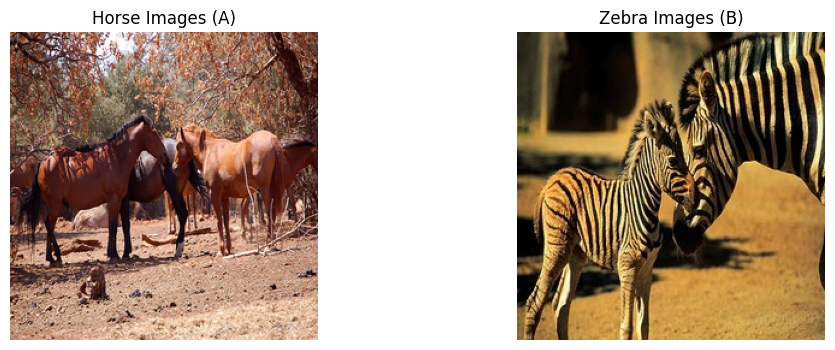

In [8]:
# ===============================
# Visualize Dataset Samples
# ===============================

def show_samples(loader, n=5):
    batch = next(iter(loader))
    real_A = batch["A"][:n]
    real_B = batch["B"][:n]

    grid_A = make_grid(real_A, nrow=n, normalize=True)
    grid_B = make_grid(real_B, nrow=n, normalize=True)

    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.title("Horse Images (A)")
    plt.imshow(grid_A.permute(1,2,0))
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.title("Zebra Images (B)")
    plt.imshow(grid_B.permute(1,2,0))
    plt.axis("off")
    plt.show()

show_samples(train_dataloader, n=5)


# <span style="color:#9370DB;">Loading Pretrained Models</span>

We provide pretrained CycleGAN weights for this assignment.

Students should find the following files inside a folder called `saved_models`:

- `G_AB.pth`
- `G_BA.pth`
- `D_A.pth`
- `D_B.pth`

These correspond to:

| Model | Description |
|------|-------------|
| G_AB | Horse → Zebra generator |
| G_BA | Zebra → Horse generator |
| D_A | Horse discriminator |
| D_B | Zebra discriminator |


# <span style="color:#9370DB;">Model Architecture (TODO)</span>

**Important:** Your architecture MUST match the provided pretrained weights.

Implement the following modules exactly (same layer order, kernel sizes, strides, paddings, normalizations, activations):

- `ResidualBlock`
- `GeneratorResNet`
- `Discriminator` (PatchGAN)


In [9]:
# ===============================
# Residual Block (TODO)
# ===============================

class ResidualBlock(nn.Module):
    def __init__(self, in_features):
        super().__init__()

        # TODO: Implement exactly:
        # ReflectionPad2d(1) -> Conv2d(in_features, in_features, 3) -> InstanceNorm2d -> ReLU
        # ReflectionPad2d(1) -> Conv2d(in_features, in_features, 3) -> InstanceNorm2d
        self.block = nn.Sequential(
            nn.ReflectionPad2d(1),
            nn.Conv2d(in_features, in_features, 3),
            nn.InstanceNorm2d(in_features),
            nn.ReLU(inplace=True),
            nn.ReflectionPad2d(1),
            nn.Conv2d(in_features, in_features, 3),
            nn.InstanceNorm2d(in_features)
        )

    def forward(self, x):
        # TODO: residual connection: return x + self.block(x)
        return x + self.block(x)

In [10]:
# ===============================
# Generator (ResNet) (TODO)
# ===============================

class GeneratorResNet(nn.Module):
    def __init__(self, input_shape, num_residual_blocks):
        super().__init__()
        channels = input_shape[0]

        # TODO: Implement exactly:
        # - Initial: ReflectionPad2d(3) -> Conv7 -> InstanceNorm -> ReLU
        # - Downsample x2: Conv stride 2 -> InstanceNorm -> ReLU (64->128->256)
        # - Residual blocks: num_residual_blocks (typically 9 for 256x256)
        # - Upsample x2: Upsample(scale=2) -> Conv3 -> InstanceNorm -> ReLU
        # - Output: ReflectionPad2d(3) -> Conv7 -> Tanh

        model = [
            nn.ReflectionPad2d(3),
            nn.Conv2d(channels, 64, 7),
            nn.InstanceNorm2d(64),
            nn.ReLU(inplace=True)]

        in_features = 64
        out_features = in_features * 2
        for _ in range(2):
            model += [
                nn.Conv2d(in_features, out_features, 3, stride=2, padding=1),
                nn.InstanceNorm2d(out_features),
                nn.ReLU(inplace=True) ]
                # nn.Conv2d(in_features, out_features, 3, stride=1, padding=1),
                # nn.InstanceNorm2d(out_features),
                # nn.ReLU(inplace=True)]
            in_features = out_features
            out_features = in_features * 2

        for _ in range(num_residual_blocks):
            model += [ResidualBlock(in_features)]
        out_features = in_features // 2
        for _ in range(2):
            model += [
                nn.Upsample(scale_factor=2),
                nn.Conv2d(in_features, out_features, 3, stride=1, padding=1),
                nn.InstanceNorm2d(out_features),
                nn.ReLU(inplace=True)]
            in_features = out_features
            out_features = in_features // 2

        model += [
            nn.ReflectionPad2d(3),
            nn.Conv2d(64, channels, 7),
            nn.Tanh() ]

        self.model = nn.Sequential(
            *model)

    def forward(self, x):
        # TODO: return self.model(x)
        return self.model(x)

In [11]:
# ===============================
# Discriminator (PatchGAN) (TODO)
# ===============================

class Discriminator(nn.Module):
    def __init__(self, input_shape):
        super().__init__()
        channels, height, width = input_shape

        self.output_shape = (1, height // 16, width // 16)

        # TODO: Implement exactly:
        # - Conv blocks: (C64, C128, C256, C512) with strides (2,2,2,1)
        # - Use InstanceNorm except first layer
        # - LeakyReLU(0.2)
        # - Final Conv to 1 channel (patch map)

        def discriminator_block(in_filters, out_filters, normalize=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalize:
                layers.append(nn.InstanceNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(channels, 64, normalize=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1))

    def forward(self, img):
        # TODO: return self.model(img)
        return self.model(img)

# <span style="color:#9370DB;">Instantiate Models + Load Pretrained Weights</span>

After you implement the architecture above, run the following cells to:

1) Create model objects  
2) Load pretrained weights from `saved_models/`


In [12]:
# ===============================
# Instantiate Models
# ===============================

channels = 3
input_shape = (channels, img_height, img_width)
n_residual_blocks = 9

G_AB = GeneratorResNet(input_shape, n_residual_blocks).to(device)  # Horse -> Zebra
G_BA = GeneratorResNet(input_shape, n_residual_blocks).to(device)  # Zebra -> Horse
D_A  = Discriminator(input_shape).to(device)
D_B  = Discriminator(input_shape).to(device)

print("Models instantiated ✅")


Models instantiated ✅


In [13]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if any(f.endswith(".pth") for f in files):
        print(root)
        print(files)

/kaggle/input/notebooks/balraj98/cyclegan-translating-horses-zebras-pytorch/saved_models
['G_AB.pth', 'G_BA.pth', 'D_A.pth', 'D_B.pth']
/kaggle/input/models/sameerrahil/d-a/tensorflow2/default/1
['G_AB.pth', 'G_BA.pth', 'D_A.pth', 'D_B.pth']


In [14]:
# ===============================
# Load Pretrained Weights
# ===============================

# IMPORTANT (Kaggle):
# Add your pretrained weights as a Kaggle dataset and set the correct path here, e.g.:
# pretrained_path = "/kaggle/input/<your-pretrained-dataset>/saved_models"
pretrained_path = "/kaggle/input/models/sameerrahil/d-a/tensorflow2/default/1"  # TODO: set correct path on Kaggle

assert os.path.isdir(pretrained_path), f"Pretrained folder not found: {pretrained_path}"
print("Pretrained files:", os.listdir(pretrained_path))

G_AB.load_state_dict(torch.load(f"{pretrained_path}/G_AB.pth", map_location=device))
G_BA.load_state_dict(torch.load(f"{pretrained_path}/G_BA.pth", map_location=device))
D_A.load_state_dict(torch.load(f"{pretrained_path}/D_A.pth", map_location=device))
D_B.load_state_dict(torch.load(f"{pretrained_path}/D_B.pth", map_location=device))

print("Pretrained models loaded ✅")


Pretrained files: ['G_AB.pth', 'G_BA.pth', 'D_A.pth', 'D_B.pth']
Pretrained models loaded ✅


# <span style="color:#9370DB;">Losses + Optimizers (Provided)</span>

We use the standard CycleGAN losses:

- GAN loss (LSGAN): `MSELoss`
- Cycle loss: `L1Loss`
- Identity loss: `L1Loss`

Optimizers: Adam with betas (0.5, 0.999)


In [15]:
# ===============================
# Loss Functions
# ===============================

criterion_GAN      = nn.MSELoss().to(device)
criterion_cycle    = nn.L1Loss().to(device)
criterion_identity = nn.L1Loss().to(device)

# ===============================
# Optimizers
# ===============================

lr = 2e-4
optimizer_G = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=lr, betas=(0.5, 0.999))
optimizer_D_A = torch.optim.Adam(D_A.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D_B = torch.optim.Adam(D_B.parameters(), lr=lr, betas=(0.5, 0.999))

print("Losses + optimizers ready ✅")


Losses + optimizers ready ✅


In [16]:
# ===============================
# Loss Tracking (for plots)
# ===============================

G_losses = []
D_A_losses = []
D_B_losses = []
cycle_losses = []
identity_losses = []


# <span style="color:#9370DB;">Ablation Study</span>

We test two configurations:

| Model | Cycle Loss | Identity Loss |
|------|------|------|
| ABL1 | Removed | Present |
| ABL2 | Present | Removed |



In [17]:
# ===============================
# Helper: Reload pretrained weights (use before each experiment)
# ===============================

def reload_pretrained_weights():
    G_AB.load_state_dict(torch.load(f"{pretrained_path}/G_AB.pth", map_location=device))
    G_BA.load_state_dict(torch.load(f"{pretrained_path}/G_BA.pth", map_location=device))
    D_A.load_state_dict(torch.load(f"{pretrained_path}/D_A.pth", map_location=device))
    D_B.load_state_dict(torch.load(f"{pretrained_path}/D_B.pth", map_location=device))


In [18]:
# ===============================
# TODO: Training Loop (one experiment)
# ===============================

def run_experiment(train_loader, n_epochs, lambda_cyc, lambda_id, lr_override=None):
    """Train CycleGAN for `n_epochs` with given lambdas and return a history dict."""

    # TODO: reload weights + reset loss lists
    # reload_pretrained_weights()
    # reset lists (G_losses, D_A_losses, D_B_losses, cycle_losses, identity_losses)
    reload_pretrained_weights()
    G_losses_local = []
    D_A_losses_local = []
    D_B_losses_local = []
    cycle_losses_local = []
    identity_losses_local = []

    # TODO: optionally override lr by recreating optimizers
    current_lr = lr_override if lr_override is not None else lr
    optimizer_G = torch.optim.Adam(itertools.chain(G_AB.parameters(), G_BA.parameters()), lr=current_lr, betas=(0.5, 0.999))
    optimizer_D_A = torch.optim.Adam(D_A.parameters(), lr=current_lr, betas=(0.5, 0.999))
    optimizer_D_B = torch.optim.Adam(D_B.parameters(), lr=current_lr, betas=(0.5, 0.999))

    # TODO: implement full CycleGAN training loop
    # - create valid/fake tensors using D_A.output_shape
    # - generator step: identity + GAN + cycle
    # - discriminator A step
    # - discriminator B step
    # - append to loss lists
    for epoch in range(n_epochs):
        G_AB.train()
        G_BA.train()
        D_A.train()
        D_B.train()
        epoch_G = 0.0
        epoch_D_A = 0.0
        epoch_D_B = 0.0
        epoch_cycle = 0.0
        epoch_identity = 0.0
        for batch in tqdm(train_loader, desc=f"epoch {epoch+1}/{n_epochs}"):
            real_A = batch["A"].to(device)
            real_B = batch["B"].to(device)

            valid = torch.ones((real_A.size(0), *D_A.output_shape), device=device)
            fake = torch.zeros((real_A.size(0), *D_A.output_shape), device=device)
            optimizer_G.zero_grad()
            loss_id_A = criterion_identity(G_BA(real_A), real_A)
            loss_id_B = criterion_identity(G_AB(real_B), real_B)
            loss_identity = (loss_id_A + loss_id_B) / 2
            fake_B = G_AB(real_A)
            loss_GAN_AB = criterion_GAN(D_B(fake_B), valid)
            fake_A = G_BA(real_B)
            loss_GAN_BA = criterion_GAN(D_A(fake_A), valid)
            loss_GAN_total = (loss_GAN_AB + loss_GAN_BA) / 2
            recov_A = G_BA(fake_B)
            loss_cycle_A = criterion_cycle(recov_A, real_A)
            recov_B = G_AB(fake_A)
            loss_cycle_B = criterion_cycle(recov_B, real_B)
            loss_cycle_total = (loss_cycle_A + loss_cycle_B) / 2
            loss_G = loss_GAN_total + lambda_cyc * loss_cycle_total + lambda_id * loss_identity
            loss_G.backward()
            optimizer_G.step()
            optimizer_D_A.zero_grad()
            loss_real_A = criterion_GAN(D_A(real_A), valid)
            loss_fake_A = criterion_GAN(D_A(fake_A.detach()), fake)
            loss_D_A = (loss_real_A + loss_fake_A) / 2
            loss_D_A.backward()
            optimizer_D_A.step()
            optimizer_D_B.zero_grad()
            loss_real_B = criterion_GAN(D_B(real_B), valid)
            loss_fake_B = criterion_GAN(D_B(fake_B.detach()), fake)
            loss_D_B = (loss_real_B + loss_fake_B) / 2
            loss_D_B.backward()
            # loss_GAN_BA = criterion_GAN(D_A(fake_A), valid)
            # loss_GAN_total = (loss_GAN_AB + loss_GAN_BA) / 2
            # recov_A = G_BA(fake_B)
            # loss_cycle_A = criterion_cycle(recov_A, real_A)
            # recov_B = G_AB(fake_A)
            optimizer_D_B.step()
            epoch_G += loss_G.item()
            epoch_D_A += loss_D_A.item()
            epoch_D_B += loss_D_B.item()
            epoch_cycle += loss_cycle_total.item()
            epoch_identity += loss_identity.item()

        num_batches = len(train_loader)
        G_losses_local.append(epoch_G / num_batches)
        D_A_losses_local.append(epoch_D_A / num_batches)
        D_B_losses_local.append(epoch_D_B / num_batches)
        cycle_losses_local.append(epoch_cycle / num_batches)
        identity_losses_local.append(epoch_identity / num_batches)
        print(f"epoch [{epoch+1}/{n_epochs}] | G: {G_losses_local[-1]:.4f} | D_A: {D_A_losses_local[-1]:.4f} | D_B: {D_B_losses_local[-1]:.4f} | cycle: {cycle_losses_local[-1]:.4f} | identity: {identity_losses_local[-1]:.4f}")

    return {
        "G_losses": G_losses_local,
        "D_A_losses": D_A_losses_local,
        "D_B_losses": D_B_losses_local,
        "cycle_losses": cycle_losses_local,
        "identity_losses": identity_losses_local
    }

In [19]:
# ===============================
# ABL1: Remove cycle loss (FAST suggestion: use fewer epochs or a subset)
# ===============================

lambda_cyc_abl1 = 0.0
lambda_id_abl1  = 5.0

# TODO:
# hist_abl1 = run_experiment(train_dataloader, n_epochs=3, lambda_cyc=lambda_cyc_abl1, lambda_id=lambda_id_abl1)
ablation_subset_size = min(400, len(train_dataloader.dataset))
ablation_indices = list(range(ablation_subset_size))
ablation_loader = DataLoader(
    torch.utils.data.Subset(train_dataloader.dataset, ablation_indices),
    batch_size=train_batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
hist_abl1 = run_experiment(ablation_loader, n_epochs=3, lambda_cyc=lambda_cyc_abl1, lambda_id=lambda_id_abl1)
G_AB_abl1 = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_BA_abl1 = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_AB_abl1.load_state_dict(G_AB.state_dict())
G_BA_abl1.load_state_dict(G_BA.state_dict())
G_AB_abl1.eval()
G_BA_abl1.eval()

epoch 1/3: 100%|██████████| 400/400 [03:54<00:00,  1.70it/s]


epoch [1/3] | G: 1.3071 | D_A: 0.2880 | D_B: 0.2415 | cycle: 0.2924 | identity: 0.1692


epoch 2/3: 100%|██████████| 400/400 [04:05<00:00,  1.63it/s]


epoch [2/3] | G: 1.2667 | D_A: 0.2635 | D_B: 0.2112 | cycle: 0.2949 | identity: 0.1639


epoch 3/3: 100%|██████████| 400/400 [04:04<00:00,  1.64it/s]


epoch [3/3] | G: 1.2619 | D_A: 0.2595 | D_B: 0.1870 | cycle: 0.3032 | identity: 0.1607


GeneratorResNet(
  (model): Sequential(
    (0): ReflectionPad2d((3, 3, 3, 3))
    (1): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1))
    (2): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (8): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (9): ReLU(inplace=True)
    (10): ResidualBlock(
      (block): Sequential(
        (0): ReflectionPad2d((1, 1, 1, 1))
        (1): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
        (2): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
        (3): ReLU(inplace=True)
        (4): ReflectionPad2d((1, 1, 1, 1))
        

In [20]:
# ===============================
# ABL2: Remove identity loss
# ===============================

lambda_cyc_abl2 = 10.0
lambda_id_abl2  = 0.0

# TODO:
# hist_abl2 = run_experiment(train_dataloader, n_epochs=3, lambda_cyc=lambda_cyc_abl2, lambda_id=lambda_id_abl2)
ablation_subset_size = min(400, len(train_dataloader.dataset))
ablation_indices = list(range(ablation_subset_size))
ablation_loader = DataLoader(
    torch.utils.data.Subset(train_dataloader.dataset, ablation_indices),
    batch_size=train_batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
hist_abl2 = run_experiment(ablation_loader, n_epochs=3, lambda_cyc=lambda_cyc_abl2, lambda_id=lambda_id_abl2)
G_AB_abl2 = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_BA_abl2 = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_AB_abl2.load_state_dict(G_AB.state_dict())
G_BA_abl2.load_state_dict(G_BA.state_dict())
G_AB_abl2.eval()
G_BA_abl2.eval()

epoch 1/3: 100%|██████████| 400/400 [04:06<00:00,  1.62it/s]


epoch [1/3] | G: 2.4451 | D_A: 0.2381 | D_B: 0.2089 | cycle: 0.1886 | identity: 0.1647


epoch 2/3: 100%|██████████| 400/400 [04:06<00:00,  1.62it/s]


epoch [2/3] | G: 2.4702 | D_A: 0.2154 | D_B: 0.1428 | cycle: 0.1870 | identity: 0.1719


epoch 3/3: 100%|██████████| 400/400 [04:06<00:00,  1.62it/s]


epoch [3/3] | G: 2.4949 | D_A: 0.2126 | D_B: 0.1461 | cycle: 0.1905 | identity: 0.1797


GeneratorResNet(
  (model): Sequential(
    (0): ReflectionPad2d((3, 3, 3, 3))
    (1): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1))
    (2): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (8): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (9): ReLU(inplace=True)
    (10): ResidualBlock(
      (block): Sequential(
        (0): ReflectionPad2d((1, 1, 1, 1))
        (1): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
        (2): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
        (3): ReLU(inplace=True)
        (4): ReflectionPad2d((1, 1, 1, 1))
        

# <span style="color:#9370DB;">Fine Tuning</span>

Fine-tune the pretrained model for **3–5 epochs** using the **complete dataset**.


In [21]:
# ===============================
# Fine-tuning Configuration
# ===============================
# Run the pretrained model with the follwoing hyperparameters to see if you can further improve the results. You can experiment with different values here. Runf for (3-5) epochs.

finetune_epochs = 5
finetune_lr = 1e-4
lambda_cyc_ft = 10.0
lambda_id_ft  = 5.0

# TODO:
# hist_ft = run_experiment(train_dataloader, n_epochs=finetune_epochs, lambda_cyc=lambda_cyc_ft, lambda_id=lambda_id_ft, lr_override=finetune_lr)
hist_ft = run_experiment(train_dataloader, n_epochs=finetune_epochs, lambda_cyc=lambda_cyc_ft, lambda_id=lambda_id_ft, lr_override=finetune_lr)
G_AB_ft = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_BA_ft = GeneratorResNet(input_shape, n_residual_blocks).to(device)
G_AB_ft.load_state_dict(G_AB.state_dict())
G_BA_ft.load_state_dict(G_BA.state_dict())
G_AB_ft.eval()
G_BA_ft.eval()
torch.save(G_AB_ft.state_dict(), "G_AB_finetuned.pth")
torch.save(G_BA_ft.state_dict(), "G_BA_finetuned.pth")

epoch 1/5: 100%|██████████| 1334/1334 [14:09<00:00,  1.57it/s]


epoch [1/5] | G: 2.6669 | D_A: 0.2023 | D_B: 0.1432 | cycle: 0.1484 | identity: 0.1243


epoch 2/5: 100%|██████████| 1334/1334 [14:07<00:00,  1.57it/s]


epoch [2/5] | G: 2.7795 | D_A: 0.1849 | D_B: 0.1378 | cycle: 0.1560 | identity: 0.1296


epoch 3/5: 100%|██████████| 1334/1334 [14:02<00:00,  1.58it/s]


epoch [3/5] | G: 2.7248 | D_A: 0.1838 | D_B: 0.1324 | cycle: 0.1512 | identity: 0.1265


epoch 4/5: 100%|██████████| 1334/1334 [14:08<00:00,  1.57it/s]


epoch [4/5] | G: 2.7660 | D_A: 0.1767 | D_B: 0.1203 | cycle: 0.1534 | identity: 0.1271


epoch 5/5: 100%|██████████| 1334/1334 [14:05<00:00,  1.58it/s]


epoch [5/5] | G: 2.7000 | D_A: 0.1801 | D_B: 0.1245 | cycle: 0.1490 | identity: 0.1243


# <span style="color:#9370DB;">Visualize Loss Curves (TODO)</span>

Plot at least:

- Generator loss
- Discriminator losses
- Cycle loss
- Identity loss


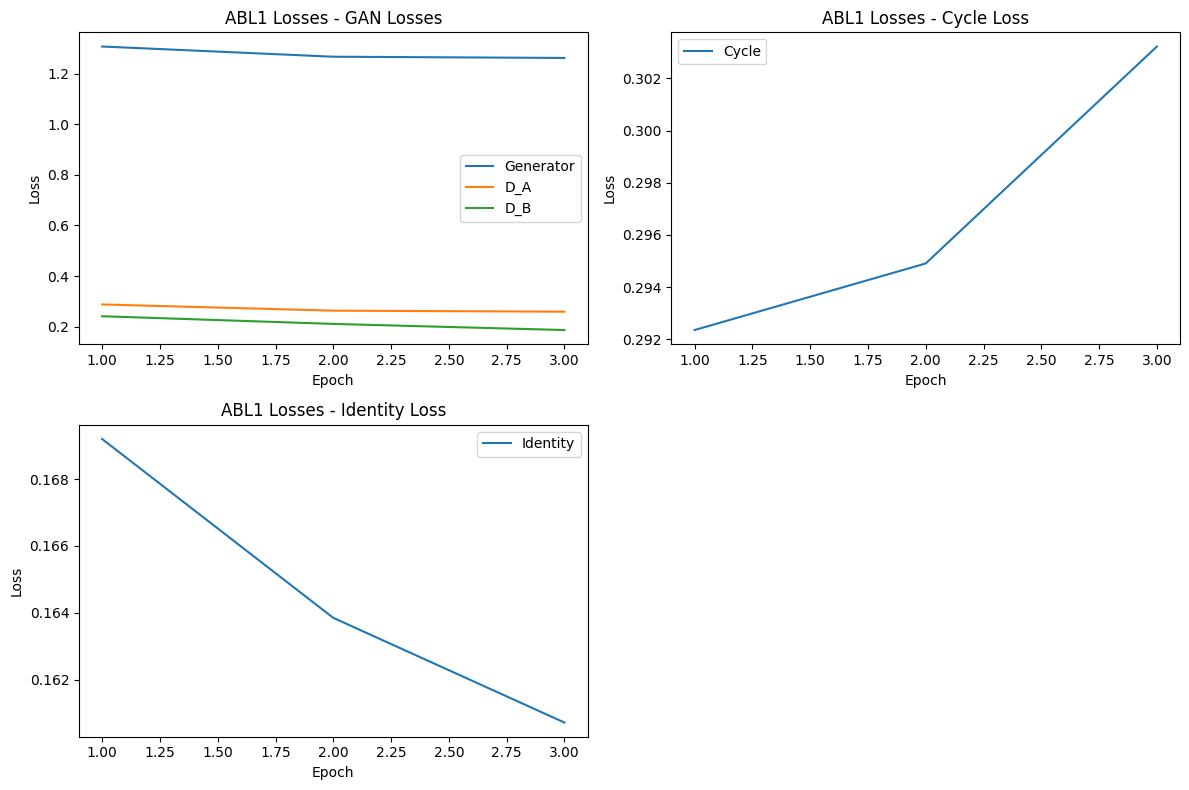

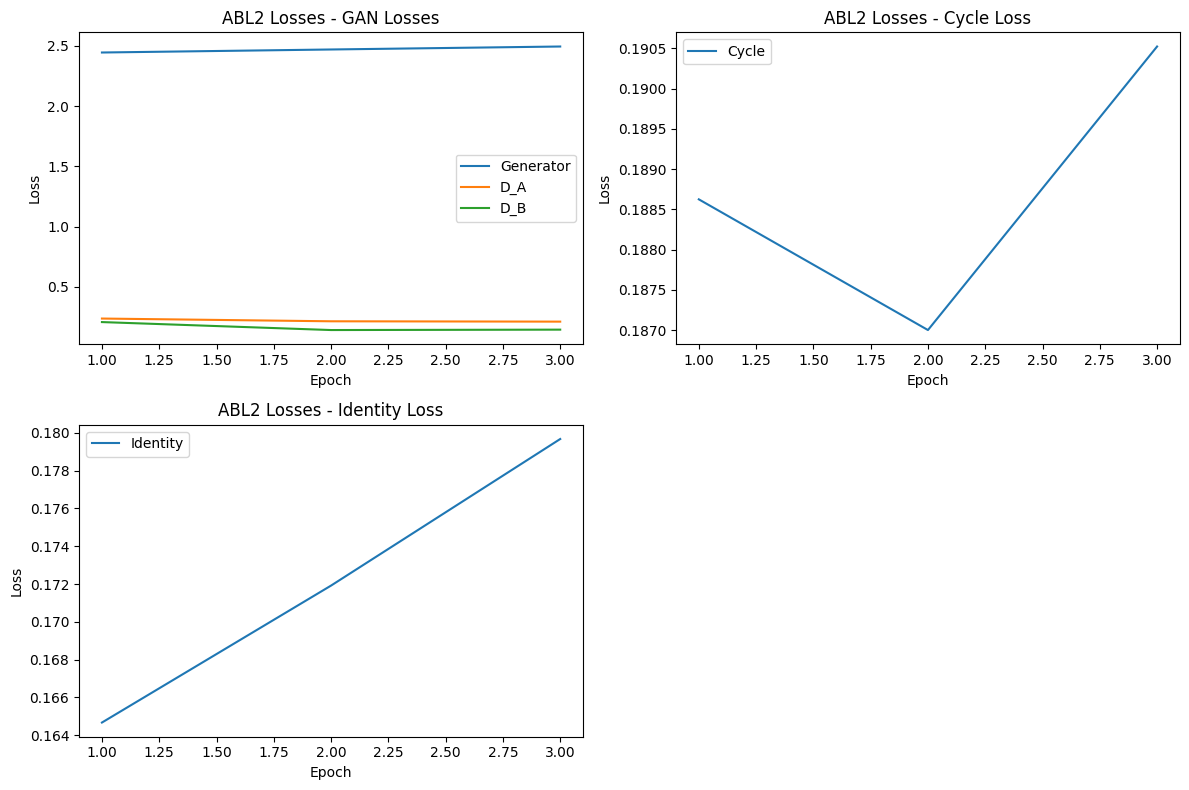

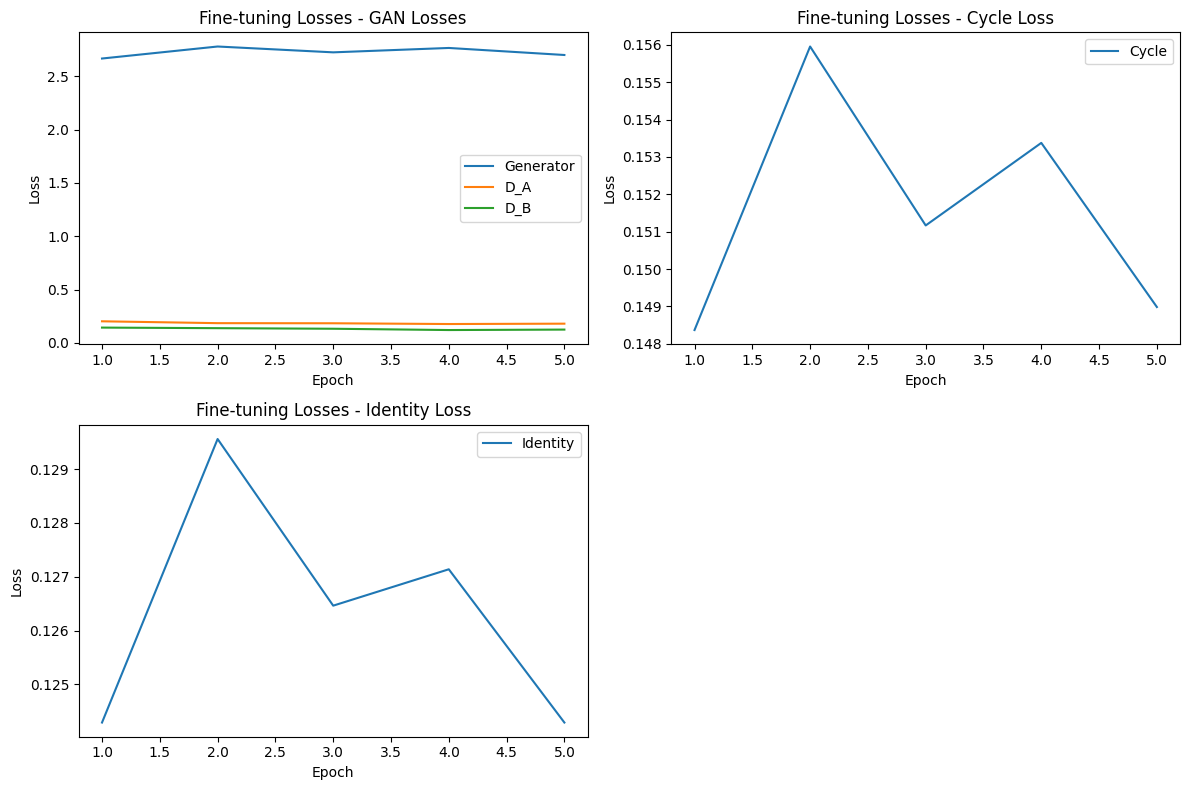

In [22]:
# ===============================
# TODO: Plot Training Losses
# ===============================

def plot_losses(history, title="Loss Curves"):
    """Implement plotting using matplotlib."""
    # TODO
    epochs = range(1, len(history["G_losses"]) + 1)
    plt.figure(figsize=(12, 8))
    plt.subplot(2, 2, 1)
    plt.plot(epochs, history["G_losses"], label="Generator")
    plt.plot(epochs, history["D_A_losses"], label="D_A")
    plt.plot(epochs, history["D_B_losses"], label="D_B")
    plt.title(f"{title} - GAN Losses")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.subplot(2, 2, 2)
    plt.plot(epochs, history["cycle_losses"], label="Cycle")
    plt.title(f"{title} - Cycle Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.subplot(2, 2, 3)
    plt.plot(epochs, history["identity_losses"], label="Identity")
    plt.title(f"{title} - Identity Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

# TODO:
plot_losses(hist_abl1, "ABL1 Losses")
plot_losses(hist_abl2, "ABL2 Losses")
plot_losses(hist_ft,   "Fine-tuning Losses")

# <span style="color:#9370DB;">Evaluation Pipeline</span>

We evaluate the performance of three models:

| Model | Description |
|------|-------------|
| **ABL1** | Cycle loss removed |
| **ABL2** | Identity loss removed |
| **Fine-tuned** | Pretrained model trained for a few additional epochs |

Two metrics are used for comparison.

---

## 1. Cycle Reconstruction Error

CycleGAN enforces **cycle consistency**, meaning an image translated to another domain and back should reconstruct the original image.

$$
\mathcal{L}_{\text{cyc}} =
\mathbb{E}_{a \sim p_A(a)}
\left[
\| a - G_{BA}(G_{AB}(a)) \|_1
\right]
+
\mathbb{E}_{b \sim p_B(b)}
\left[
\| b - G_{AB}(G_{BA}(b)) \|_1
\right]
$$

---

## 2. Frechet Inception Distance (FID)

FID measures how similar the **generated image distribution** is to the **real image distribution** using features extracted from an **Inception-V3 network**.

$$
\mathrm{FID}(r,g) =
\|\mu_r - \mu_g\|_2^2 +
\mathrm{Tr}\!\left(
\Sigma_r + \Sigma_g -
2(\Sigma_r \Sigma_g)^{1/2}
\right)
$$

---

## What to Report

For each model (**ABL1**, **ABL2**, **Fine-tuned**), report:

- **Cycle Reconstruction Error** 
- **FID score** for Horse → Zebra translation

Use these metrics to analyze how removing different loss components affects model performance.

In [23]:
# ===============================
# Helpers
# ===============================

@torch.no_grad()
def denorm(x):
    return (x * 0.5 + 0.5).clamp(0, 1)


In [24]:
# ===============================
# TODO: Cycle Reconstruction Error
# ===============================

@torch.no_grad()
def cycle_reconstruction_error(G_AB, G_BA, loader, max_batches=50):
    # TODO
    G_AB.eval()
    G_BA.eval()
    total_error = 0.0
    total_count = 0
    for i, batch in enumerate(loader):
        if i >= max_batches:
            break
        real_A = batch["A"].to(device)
        real_B = batch["B"].to(device)
        rec_A = G_BA(G_AB(real_A))
        rec_B = G_AB(G_BA(real_B))
        err_A = torch.mean(torch.abs(rec_A - real_A)).item()
        err_B = torch.mean(torch.abs(rec_B - real_B)).item()
        total_error += err_A + err_B
        total_count += 2
    return total_error / total_count

# <span style="color:#9370DB;">Qualitative Comparison (TODO)</span>

Create a grid showing:

1) Real Horse (A)
2) Fake Zebra (ABL1)
3) Fake Zebra (ABL2)
4) Fake Zebra (Fine-tuned)
5) Real Zebra (B)


In [ ]:
#BRO THIS DID NTO WORK I TRIED FOR 1 WHOLE DAY I HAVE EID TOMORROW PLZ IM ASKIGN AI FOR HELP NOW WHY GAVE SUCH A LONG ASSIGNMENT

# # ===============================
# # TODO: Frechet Inception Distance (FID)
# # ===============================

# # Hint: torchmetrics is allowed.
# # If needed:
# # !pip -q install torchmetrics[image]
# # from torchmetrics.image.fid import FrechetInceptionDistance

# @torch.no_grad()
# def compute_fid_A2B(G_AB, loader, max_batches=50):
#     # TODO
#     try:
#         from torchmetrics.image.fid import FrechetInceptionDistance
#     except:
#         import sys
#         import subprocess
#         subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "torchmetrics[image]", "torch-fidelity"])
#         from torchmetrics.image.fid import FrechetInceptionDistance
#     G_AB.eval()
#     fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
#     for i, batch in enumerate(loader):
#         if i >= max_batches:
#             break
#         real_A = batch["A"].to(device)
#         real_B = batch["B"].to(device)
#         fake_B = G_AB(real_A)
#         real_imgs = (denorm(real_B) * 255).to(torch.uint8)
#         fake_imgs = (denorm(fake_B) * 255).to(torch.uint8)
#         fid.update(real_imgs, real=True)
#         fid.update(fake_imgs, real=False)
#     return fid.compute().item()

In [40]:
# ===============================
# TODO: Frechet Inception Distance (FID)
# ===============================

# Hint: torchmetrics is allowed.
# If needed:
# !pip -q install torchmetrics[image]
# from torchmetrics.image.fid import FrechetInceptionDistance

from torchvision.models import inception_v3, Inception_V3_Weights
from scipy.linalg import sqrtm

@torch.no_grad()
def compute_fid_A2B(G_AB, loader, max_batches=50):
    # TODO
    G_AB.eval()
    inception = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False).to(device)
    inception.fc = nn.Identity()
    inception.eval()

    resize = transforms.Resize((299, 299))
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    real_features = []
    fake_features = []

    for i, batch in enumerate(loader):
        if i >= max_batches:
            break

        real_A = batch["A"].to(device)
        real_B = batch["B"].to(device)
        fake_B = G_AB(real_A)

        real_imgs = denorm(real_B)
        fake_imgs = denorm(fake_B)

        real_imgs = resize(real_imgs)
        fake_imgs = resize(fake_imgs)

        real_imgs = (real_imgs - mean) / std
        fake_imgs = (fake_imgs - mean) / std

        real_feat = inception(real_imgs)
        fake_feat = inception(fake_imgs)

        real_features.append(real_feat.detach().cpu().numpy())
        fake_features.append(fake_feat.detach().cpu().numpy())

    real_features = np.concatenate(real_features, axis=0)
    fake_features = np.concatenate(fake_features, axis=0)

    mu_real = np.mean(real_features, axis=0)
    mu_fake = np.mean(fake_features, axis=0)

    sigma_real = np.cov(real_features, rowvar=False)
    sigma_fake = np.cov(fake_features, rowvar=False)

    covmean = sqrtm(sigma_real @ sigma_fake)
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = np.sum((mu_real - mu_fake) ** 2) + np.trace(sigma_real + sigma_fake - 2 * covmean)
    return float(fid)

In [31]:
!pip -q install torchmetrics[image] torch-fidelity

In [32]:
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-fidelity", "torchmetrics[image]"])
print("install done")

install done


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 174MB/s]  


abl1 cycle reconstruction error: 0.34141044983906405
abl2 cycle reconstruction error: 0.1713710884962763
fine-tuned cycle reconstruction error: 0.14752843084612063
abl1 fid: 156.32148565350326
abl2 fid: 173.8060867187516
fine-tuned fid: 143.5573936261792


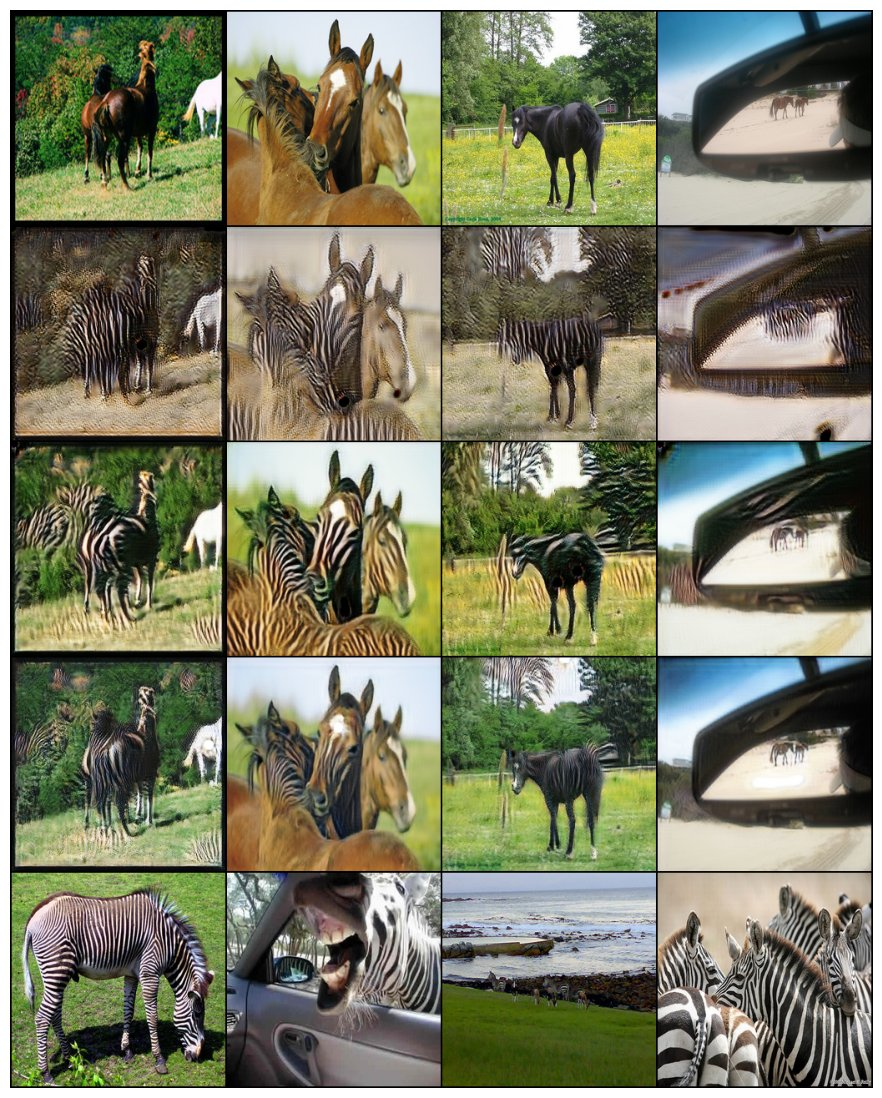

In [41]:
# ===============================
# TODO: Comparison Grid
# ===============================

@torch.no_grad()
def compare_models(G_AB_abl1, G_AB_abl2, G_AB_ft, loader, n=4):
    # TODO
    G_AB_abl1.eval()
    G_AB_abl2.eval()
    G_AB_ft.eval()
    batch = next(iter(loader))
    real_A = batch["A"][:n].to(device)
    real_B = batch["B"][:n].to(device)
    fake_B_abl1 = G_AB_abl1(real_A)
    fake_B_abl2 = G_AB_abl2(real_A)
    fake_B_ft = G_AB_ft(real_A)
    comparison = torch.cat([
        denorm(real_A).cpu(),
        denorm(fake_B_abl1).cpu(),
        denorm(fake_B_abl2).cpu(),
        denorm(fake_B_ft).cpu(),
        denorm(real_B).cpu()
    ], dim=0)
    grid = make_grid(comparison, nrow=n, normalize=False)
    plt.figure(figsize=(4 * n, 14))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.show()
    # i implemented it bro no more notimplemented err ffs leave me alone


cre_abl1 = cycle_reconstruction_error(G_AB_abl1, G_BA_abl1, test_dataloader)
cre_abl2 = cycle_reconstruction_error(G_AB_abl2, G_BA_abl2, test_dataloader)
cre_ft = cycle_reconstruction_error(G_AB_ft, G_BA_ft, test_dataloader)

fid_abl1 = compute_fid_A2B(G_AB_abl1, test_dataloader)
fid_abl2 = compute_fid_A2B(G_AB_abl2, test_dataloader)
fid_ft = compute_fid_A2B(G_AB_ft, test_dataloader)

print("abl1 cycle reconstruction error:", cre_abl1)
print("abl2 cycle reconstruction error:", cre_abl2)
print("fine-tuned cycle reconstruction error:", cre_ft)

print("abl1 fid:", fid_abl1)
print("abl2 fid:", fid_abl2)
print("fine-tuned fid:", fid_ft)

compare_models(G_AB_abl1, G_AB_abl2, G_AB_ft, test_dataloader, n=4)


# <span style="color:#9370DB;">Analysis</span>

In **your own words**, answer:

1. What happens when cycle consistency loss is removed?
2. How does identity loss affect the generated images?
3. Why is cycle loss important for stable translation?
4. Compare results between ablation and pretrained/fine-tuned models.

Provide a short analysis (4–6 sentences) covering answers to above questions and refer to your **FID** and **cycle reconstruction error** values.


#### ANSWER ANALYSIS HERE
when cycle consistency loss is removed, the model loses its ability to preserve the original structure of the input image, so the translation becomes much less reliable and more distorted. this is clearly visible in abl1, which has the worst cycle reconstruction error at 0.3414, much higher than abl2 at 0.1714 and the fine-tuned model at 0.1475, showing that it struggles to map horse to zebra and back in a meaningful way. identity loss helps preserve domain-specific properties such as color, brightness, and overall appearance, so when it is removed in abl2, the model still translates better than abl1 structurally, but the generated images can drift more in style and realism, which is also reflected in its worse fid score of 173.81 compared to abl1 at 156.32. cycle loss is important for stable translation because it forces the mapping to remain consistent and prevents the generators from producing arbitrary outputs. overall, the fine-tuned model performs best, with both the lowest cycle reconstruction error and the best fid score of 143.56, showing that using all major losses together leads to the most stable and visually convincing translations.